# ES 0DTE stale quotes: results

Answers research questions 1-3 from the README. All logic lives in `src/stale_quotes/metrics.py`; this notebook only loads and displays its outputs.

**Before running:** cache the data and build the per-date tables once:

```bash
python scripts/download.py
python scripts/run_study.py        # writes data/processed/{stale,latency}/ and results/
```

Definitions (details in the `metrics` and `staleness` docstrings):

| Measure | Definition |
|---|---|
| Reaction latency | `t0` to the option's first top-of-book price change after the futures move (size-only updates ignored). The directional version needs the mid to move the way delta says. |
| Censoring | Each (event, option) pair is followed until the next futures move, the 10 ms horizon, a data gap, or expiry. Quantiles are Kaplan-Meier, so censored pairs are not dropped. Blank quantiles mean censoring stopped the curve before that level. |
| Opportunity rate | Share of futures events with at least one option stale after costs (half an option tick + $1.00 fee). |
| Stale-window duration | `t0` until the stale side is re-priced past the threshold or pulled (#6). |
| Edge | Points after costs; `capacity_usd` = edge in $ x displayed size. |

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Locate the project root
cwd = Path.cwd().resolve()
ROOT = cwd if (cwd / "src" / "stale_quotes").is_dir() else cwd.parent

# Add src/ to the Python import path
sys.path.insert(0, str(ROOT / "src"))

from stale_quotes import config, metrics

pd.set_option("display.float_format", "{:,.3f}".format)

stale, latency = metrics.load_processed(config.PROCESSED_DIR)
tables = metrics.build_tables(stale, latency)

print(
    f"{stale['trading_date'].nunique()} days, "
    f"{stale.groupby(['trading_date', 'event_id']).ngroups:,} futures events, "
    f"{stale['instrument_id'].nunique()} options, "
    f"{len(stale):,} (event, option) pairs"
)

5 days, 302,485 futures events, 100 options, 6,049,700 (event, option) pairs


## Data coverage

Share of pairs per status. Pairs that cannot be judged (`no_quote`, `invalid_quote`, black76 failures such as `below_intrinsic` or `low_vega`) are excluded from the rates below, so check that they are not concentrated in one moneyness bucket or time of day.

In [2]:
display(tables["status_overall"])
display(tables["status_moneyness"])
display(tables["status_session"])

status,pairs,not_stale,invalid_quote,below_intrinsic,stale,no_solution,no_quote
group,,,,,,,
all,6049700,0.959,0.019,0.017,0.005,0.000,0.000


status,pairs,below_intrinsic,invalid_quote,no_quote,no_solution,not_stale,stale
moneyness,,,,,,,
ITM >7.5,2311975,0.044,0.002,0.000,0.000,0.948,0.005
ITM 2.5-7.5,477568,0.004,0.001,0.000,0.000,0.981,0.013
ATM,483015,0.000,0.003,0.000,0.000,0.988,0.009
OTM 2.5-7.5,477256,0.000,0.007,0.000,0.000,0.984,0.008
OTM 7.5-17.5,828887,0.000,0.014,0.000,0.000,0.984,0.002
OTM >17.5,1470999,0.000,0.063,0.000,0.000,0.937,0.000


status,pairs,below_intrinsic,invalid_quote,no_quote,no_solution,not_stale,stale
session,,,,,,,
open,1203940,0.000,0.000,0.000,0.000,0.996,0.004
morning,1865120,0.001,0.000,0.000,0.000,0.992,0.007
midday,1889500,0.004,0.002,0.000,0.000,0.991,0.003
afternoon,697880,0.043,0.001,0.000,0.000,0.952,0.004
close,393260,0.167,0.277,0.000,0.003,0.550,0.003


## RQ1: How quickly do option quotes react?

`zero_latency_share` is the share of reactions stamped at exactly `t0`. Futures and options run on different matching engines (issue #1), so a large share, or reactions that look faster than physically possible, means microsecond latencies should be read at a coarser horizon.

In [3]:
display(tables["latency_overall"])
display(tables["latency_moneyness"])
display(tables["latency_session"])
display(tables["latency_move"])

,pairs,censored_share,zero_latency_share,p10_us,p25_us,p50_us,p75_us,p90_us
group,,,,,,,,
all,5935730,0.785,0.000,224.248,"5,012.544",NaN,NaN,NaN


,pairs,censored_share,zero_latency_share,p10_us,p25_us,p50_us,p75_us,p90_us
moneyness,,,,,,,,
ITM >7.5,2307090,0.777,0.000,222.154,"3,508.866",NaN,NaN,NaN
ITM 2.5-7.5,476880,0.709,0.000,132.346,610.936,NaN,NaN,NaN
ATM,481511,0.695,0.000,116.800,476.596,NaN,NaN,NaN
OTM 2.5-7.5,473815,0.724,0.000,131.888,861.070,NaN,NaN,NaN
OTM 7.5-17.5,817437,0.768,0.000,196.162,"3,064.410",NaN,NaN,NaN
OTM >17.5,1378997,0.886,0.000,"1,056.590",NaN,NaN,NaN,NaN


,pairs,censored_share,zero_latency_share,p10_us,p25_us,p50_us,p75_us,p90_us
session,,,,,,,,
open,1203618,0.765,0.000,209.714,"3,654.018",NaN,NaN,NaN
morning,1864809,0.768,0.000,189.454,"2,429.030",NaN,NaN,NaN
midday,1886043,0.799,0.000,251.674,"8,091.402",NaN,NaN,NaN
afternoon,696853,0.812,0.000,245.190,"9,668.844",NaN,NaN,NaN
close,284407,0.813,0.000,245.448,"9,612.070",NaN,NaN,NaN


,pairs,censored_share,zero_latency_share,p10_us,p25_us,p50_us,p75_us,p90_us
move_bucket,,,,,,,,
<1,5694426,0.790,0.000,217.858,"6,271.564",NaN,NaN,NaN
1,233124,0.676,0.000,301.208,533.412,NaN,NaN,NaN
1.5-2,5709,0.487,0.000,439.064,523.414,676.546,"1,643.962",NaN
2.5-4,1985,0.348,0.000,596.850,700.152,954.828,"1,260.652",NaN
>4,486,0.436,0.000,974.542,"1,236.618","1,860.460","3,095.092","4,688.722"


,pairs,censored_share,zero_latency_share,p10_us,p25_us,p50_us,p75_us,p90_us
moneyness,,,,,,,,
ITM >7.5,2307090,0.786,0.000,233.944,"4,923.532",NaN,NaN,NaN
ITM 2.5-7.5,476880,0.721,0.000,136.922,719.646,NaN,NaN,NaN
ATM,481511,0.705,0.000,120.020,520.136,NaN,NaN,NaN
OTM 2.5-7.5,473815,0.733,0.000,137.452,"1,036.796",NaN,NaN,NaN
OTM 7.5-17.5,817437,0.777,0.000,210.242,"3,967.100",NaN,NaN,NaN
OTM >17.5,1378997,0.893,0.000,"1,316.016",NaN,NaN,NaN,NaN


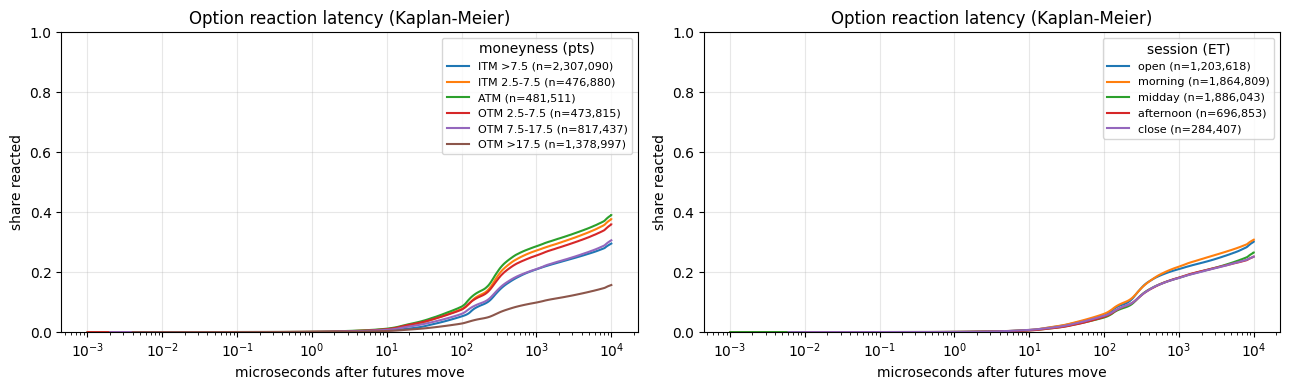

In [4]:
display(tables["directional_latency_moneyness"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
metrics.plot_latency(latency, "moneyness", ax=axes[0])
metrics.plot_latency(latency, "session", ax=axes[1])
fig.tight_layout()

## RQ2: How often do futures moves leave a stale quote?

`event_rate` counts each futures move once, however many options it leaves stale. The hypothesis predicts low rates for sub-tick and single-tick moves and much higher rates for multi-tick moves.

,events,stale_events,event_rate,pairs,stale_pairs,pair_rate
move_bucket,,,,,,
<1,288768,76,0.000,5598183,76,0.000
1,12096,7349,0.608,224340,24000,0.107
1.5-2,296,241,0.814,5460,2784,0.510
2.5-4,104,96,0.923,1929,1490,0.772
>4,25,24,0.960,477,410,0.860


,events,stale_events,event_rate,pairs,stale_pairs,pair_rate
moneyness,,,,,,
ITM >7.5,299871,5645,0.019,2204085,12313,0.006
ITM 2.5-7.5,266238,4861,0.018,474824,6136,0.013
ATM,241349,3173,0.013,481248,4219,0.009
OTM 2.5-7.5,266267,3380,0.013,473808,3993,0.008
OTM 7.5-17.5,283537,1157,0.004,817427,1626,0.002
OTM >17.5,291817,192,0.001,1378997,473,0.000


,events,stale_events,event_rate,pairs,stale_pairs,pair_rate
session,,,,,,
open,60196,1169,0.019,1203476,4575,0.004
morning,93256,3397,0.036,1863676,13634,0.007
midday,94475,1787,0.019,1878532,6455,0.003
afternoon,34894,1014,0.029,667182,3021,0.005
close,18468,419,0.023,217523,1075,0.005


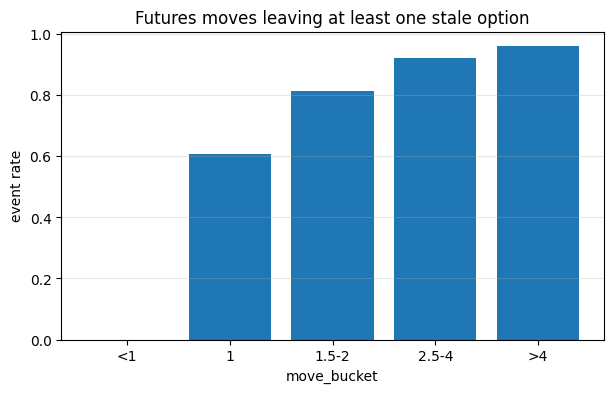

In [5]:
display(tables["opportunity_move"])
display(tables["opportunity_moneyness"])
display(tables["opportunity_session"])
metrics.plot_rate(tables["opportunity_move"], title="Futures moves leaving at least one stale option");

## RQ3: How long do stale quotes survive?

,stale_pairs,censored_share,p10_us,p25_us,p50_us,p75_us,p90_us
group,,,,,,,
all,28760,0.470,243.648,398.820,772.116,NaN,NaN


,stale_pairs,censored_share,p10_us,p25_us,p50_us,p75_us,p90_us
move_bucket,,,,,,,
<1,76,0.342,10.562,64.466,215.492,"6,314.150",NaN
1,24000,0.486,224.992,356.844,710.372,NaN,NaN
1.5-2,2784,0.352,493.440,569.404,672.744,909.190,"1,460.554"
2.5-4,1490,0.394,717.354,824.740,"1,060.200","1,319.568","3,673.770"
>4,410,0.644,"1,265.236","1,422.676",NaN,NaN,NaN


,stale_pairs,censored_share,p10_us,p25_us,p50_us,p75_us,p90_us
moneyness,,,,,,,
ITM >7.5,12313,0.481,259.130,425.532,812.426,NaN,NaN
ITM 2.5-7.5,6136,0.545,256.754,426.376,"1,177.338",NaN,NaN
ATM,4219,0.408,176.164,329.304,589.976,"8,093.326",NaN
OTM 2.5-7.5,3993,0.439,227.160,351.054,641.744,NaN,NaN
OTM 7.5-17.5,1626,0.368,247.466,430.694,688.184,"1,750.538",NaN
OTM >17.5,473,0.381,525.270,652.438,"1,003.776","1,878.360",NaN


,stale_pairs,censored_share,p10_us,p25_us,p50_us,p75_us,p90_us
session,,,,,,,
open,4575,0.430,235.476,366.600,685.362,"9,133.482",NaN
morning,13634,0.483,247.140,398.950,828.996,NaN,NaN
midday,6455,0.474,243.038,416.266,776.546,NaN,NaN
afternoon,3021,0.468,243.710,411.940,762.902,NaN,NaN
close,1075,0.462,238.770,414.162,643.904,NaN,NaN


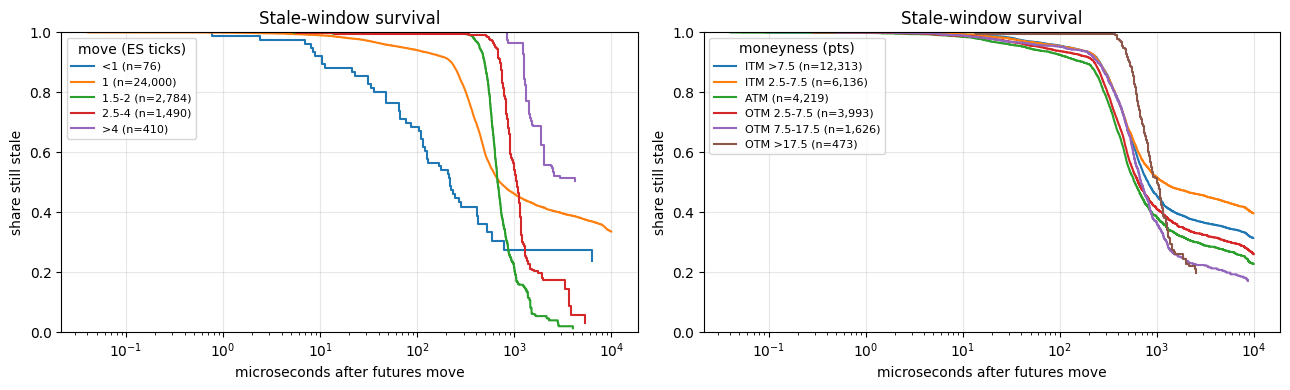

In [6]:
display(tables["duration_overall"])
display(tables["duration_move"])
display(tables["duration_moneyness"])
display(tables["duration_session"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
metrics.plot_survival(stale, "move_bucket", ax=axes[0])
metrics.plot_survival(stale, "moneyness", ax=axes[1])
fig.tight_layout()

## Is the edge worth it after costs?

,stale_pairs,mean_edge_pts,median_edge_pts,p90_edge_pts,median_edge_usd,median_quote_size,total_capacity_usd
group,,,,,,,
all,28760,0.050,0.019,0.085,0.951,8.000,"1,187,443.816"


,stale_pairs,mean_edge_pts,median_edge_pts,p90_edge_pts,median_edge_usd,median_quote_size,total_capacity_usd
move_bucket,,,,,,,
<1,76,0.004,0.002,0.009,0.093,1.000,19.006
1,24000,0.019,0.016,0.038,0.803,6.000,"230,693.654"
1.5-2,2784,0.085,0.073,0.176,3.631,12.000,"188,938.254"
2.5-4,1490,0.240,0.229,0.431,11.457,12.000,"306,915.335"
>4,410,0.955,0.689,1.992,34.428,14.000,"460,877.568"


,stale_pairs,mean_edge_pts,median_edge_pts,p90_edge_pts,median_edge_usd,median_quote_size,total_capacity_usd
moneyness,,,,,,,
ITM >7.5,12313,0.066,0.023,0.141,1.144,5.000,"405,354.422"
ITM 2.5-7.5,6136,0.033,0.010,0.059,0.511,6.000,"108,037.013"
ATM,4219,0.046,0.027,0.062,1.370,8.000,"186,407.864"
OTM 2.5-7.5,3993,0.027,0.011,0.033,0.535,18.000,"189,164.405"
OTM 7.5-17.5,1626,0.055,0.007,0.131,0.369,19.000,"203,230.112"
OTM >17.5,473,0.076,0.035,0.147,1.751,33.000,"95,250.000"


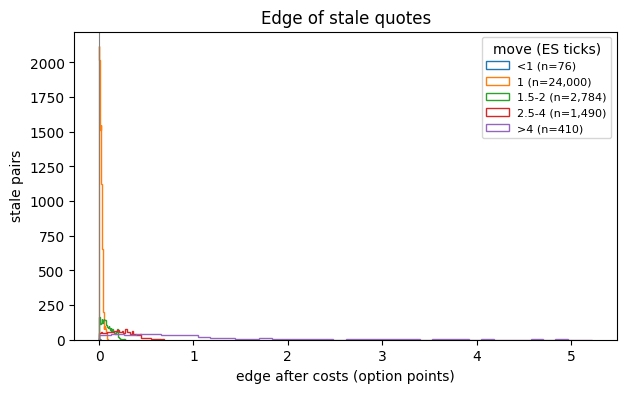

In [7]:
display(tables["edge_overall"])
display(tables["edge_move"])
display(tables["edge_moneyness"])
metrics.plot_edge(stale);

## Answers

To be filled in from the outputs above once `run_study.py` has run on the full Oct 5-9 sample:

1. **Reaction latency:**
2. **Opportunity frequency:**
3. **Window duration:**
4. **Variation by move size, moneyness and time of day:**